# Results notebook: an SE-ResNet-26 under 5M parameters for CIFAR-10

Team **Punters**: Uvindu Salgado (uis202@nyu.edu), Michael Wang (mzw2010@nyu.edu)

This notebook backs up the numbers in our report. It does not train anything; all training ran on Kaggle T4 GPUs,
and those notebooks are in `kaggle_runs/`. Here we:

1. Print the **parameter count** of each network we trained and check it against the 5M limit.
2. Load our saved weights and **recompute validation accuracy** on the same 5,000 held out images (seed 0).
3. **Rebuild both submitted prediction files** from the final weights and check they match what we uploaded.
4. Print the **final test accuracy** (our Kaggle scores) and the table of every run.
5. Make the figures in the report: training curves, validation against leaderboard accuracy, the robustness
   scorecard, how the test images differ from the training images, and how noisy the leaderboard is.

**To run it:** put the competition files in `data/` (`train_labels.csv`, `test.csv`, `sample_submission.csv`,
`train_images/`, `test_images/`; see the README). A CPU is enough (about 15 minutes); a GPU is used if there is one.

In [1]:
import os, re, glob, time, inspect, hashlib
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
import models

DATA = "data"
DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_grad_enabled(False)
os.makedirs("figures", exist_ok=True); os.makedirs("results/regenerated", exist_ok=True)
print("device:", DEV, "| torch", torch.__version__)

# One color per run, the same in every figure. The palette is checked for color blind readers.
COL = {"v2": "#2a78d6", "v4": "#eb6834", "robust": "#1baf7a", "v1": "#eda100",
       "v3_sam": "#e87ba4", "kd": "#008300", "augmix": "#6250d6", "hardview": "#e34948"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 8.5, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "legend.frameon": False,
                     "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight", "lines.linewidth": 1.6})
def save(fig, name):
    fig.savefig(f"figures/{name}.pdf"); fig.savefig(f"figures/{name}.png")

device: cpu | torch 2.15.0+cu132


## 1. Parameter counts (limit: 5,000,000 trainable parameters)

In [2]:
# models.py is an exact copy of the model code in train.py, the script that trained the final models.
train_src = open("train.py").read()
block = train_src[train_src.index("class SE(nn.Module):"):train_src.index("def make_model(spec):")]
assert block in open("models.py").read(), "models.py drifted from train.py"
print("models.py matches the model code in train.py\n")

archs = {
    "v1  ResNet-14 [80,160,320] x [2,2,2]":            models.ResNet([80, 160, 320], [2, 2, 2]),
    "v2  ResNet-24 [64,128,256] x [4,4,3]":            models.make_model("resnet-4-4-3"),
    "v4  SE-ResNet-26 [64,128,256] x [5,4,3]  (final)": models.make_model("resnet-5-4-3-se"),
    "WRN-28-10 (teacher we considered, never trained)": models.make_model("wrn-28-10"),
}
for name, m in archs.items():
    n = models.count_params(m)
    print(f"{name:52s} {n:>12,}  {'under the limit' if n <= 5_000_000 else 'over 5M, not allowed as a final model'}")

final = models.make_model("resnet-5-4-3-se")
N_FINAL = models.count_params(final)
assert N_FINAL == 4_810_754 and N_FINAL <= 5_000_000
print(f"\nFINAL MODEL (both submissions): SE-ResNet-26, trainable parameters = {N_FINAL:,}")

# how the parameters are spread across the network
rows = [("stem", final.stem)] + [(f"layers[{i}]", b) for i, b in enumerate(final.layers)] + [("fc", final.fc)]
stage = {"stem": 0}
for name, mod in rows:
    stage[name] = models.count_params(mod)
by_stage = {"stem (3x3 conv, 64)": stage["stem"],
            "stage 1: 5 blocks @ 64ch, 32x32": sum(stage[f"layers[{i}]"] for i in range(0, 5)),
            "stage 2: 4 blocks @ 128ch, 16x16": sum(stage[f"layers[{i}]"] for i in range(5, 9)),
            "stage 3: 3 blocks @ 256ch, 8x8": sum(stage[f"layers[{i}]"] for i in range(9, 12)),
            "average pool and linear layer (256 to 10)": stage["fc"]}
se_params = sum(models.count_params(b.se) for b in final.layers)
for k, v in by_stage.items():
    print(f"  {k:36s} {v:>10,}  ({100 * v / N_FINAL:4.1f}%)")
print(f"  of this, the SE gates use {se_params:,} ({100 * se_params / N_FINAL:.1f}%)")

models.py matches the model code in train.py



v1  ResNet-14 [80,160,320] x [2,2,2]                    4,337,370  under the limit
v2  ResNet-24 [64,128,256] x [4,4,3]                    4,697,162  under the limit
v4  SE-ResNet-26 [64,128,256] x [5,4,3]  (final)        4,810,754  under the limit
WRN-28-10 (teacher we considered, never trained)       36,479,194  over 5M, not allowed as a final model

FINAL MODEL (both submissions): SE-ResNet-26, trainable parameters = 4,810,754
  stem (3x3 conv, 64)                       1,856  ( 0.0%)
  stage 1: 5 blocks @ 64ch, 32x32         375,400  ( 7.8%)
  stage 2: 4 blocks @ 128ch, 16x16      1,125,152  (23.4%)
  stage 3: 3 blocks @ 256ch, 8x8        3,305,776  (68.7%)
  average pool and linear layer (256 to 10)      2,570  ( 0.1%)
  of this, the SE gates use 39,608 (0.8%)


## 2. Data and the validation split

In [3]:
def load(folder, names):
    return np.stack([np.asarray(Image.open(os.path.join(DATA, folder, f)).convert("RGB")) for f in names])

cache = os.path.join(DATA, "_cache.npz")
train_df = pd.read_csv(f"{DATA}/train_labels.csv"); test_df = pd.read_csv(f"{DATA}/test.csv")
sample = pd.read_csv(f"{DATA}/sample_submission.csv")
if os.path.exists(cache):
    z = np.load(cache); X, Xte = z["X"], z["Xte"]
else:
    t = time.time(); X = load("train_images", train_df.filename); Xte = load("test_images", test_df.filename)
    np.savez(cache, X=X, Xte=Xte); print(f"loaded the PNG files in {time.time() - t:.0f}s")
y = train_df.label.values
np.random.seed(0); perm = np.random.permutation(len(X))      # the same split train.py makes with seed 0
val_idx, tr_idx = perm[:5000], perm[5000:]
print("train", X.shape, "| test", Xte.shape, "| validation", len(val_idx), "images, per class:", np.bincount(y[val_idx]))

def stats(idx):  # per channel mean and std, computed in float64 as in train.py
    a = X[idx].reshape(-1, 3)
    return a.mean(0, dtype=np.float64) / 255, a.std(0, dtype=np.float64) / 255
NORM = {"45k": stats(tr_idx), "50k": stats(np.arange(len(X)))}

train (50000, 32, 32, 3) | test (2000, 32, 32, 3) | validation 5000 images, per class: [503 483 487 527 473 548 491 502 482 504]


## 3. Recompute validation accuracy from the saved weights

In [4]:
def predict(net, X_u8, norm, tta=False, bs=500):
    # Same as train.py: average the softmax over the image and its mirror, and over 2 pixel shifts when tta=True (10 views)
    mean = torch.tensor(norm[0], dtype=torch.float32, device=DEV).view(1, 3, 1, 1)
    std = torch.tensor(norm[1], dtype=torch.float32, device=DEV).view(1, 3, 1, 1)
    net = net.to(DEV).eval(); out = []
    shifts = [(0, 0), (2, 0), (-2, 0), (0, 2), (0, -2)] if tta else [(0, 0)]
    for k in range(0, len(X_u8), bs):
        x = torch.from_numpy(X_u8[k:k + bs]).to(DEV).permute(0, 3, 1, 2).float().div(255)
        xp = F.pad((x - mean) / std, (2, 2, 2, 2), mode="reflect"); p = 0
        for dy, dx in shifts:
            v = xp[:, :, 2 + dy:34 + dy, 2 + dx:34 + dx]
            p = p + net(v).softmax(1) + net(v.flip(3)).softmax(1)
        out.append(p / (2 * len(shifts)))
    return torch.cat(out).cpu().numpy()

def load_ckpt(spec, path):
    m = models.make_model(spec); m.load_state_dict(torch.load(path, map_location="cpu")); return m

runs = pd.read_csv("results/runs.csv").set_index("run")
val_ckpts = {"v2": ("resnet-4-4-3", "checkpoints/v2.pt"),
             "v4_val": ("resnet-5-4-3-se", "checkpoints/v4_val.pt"),
             "robust_val": ("resnet-5-4-3-se", "checkpoints/robust_val.pt")}
recomputed = {}
for run, (spec, path) in val_ckpts.items():
    t = time.time()
    acc = (predict(load_ckpt(spec, path), X[val_idx], NORM["45k"]).argmax(1) == y[val_idx]).mean()
    recomputed[run] = acc
    print(f"{run:11s} validation accuracy = {acc:.4f}   (Kaggle log said {runs.loc[run, 'val_flip']:.4f})   {time.time() - t:.0f}s")

v2          validation accuracy = 0.9740   (Kaggle log said 0.9740)   78s


v4_val      validation accuracy = 0.9790   (Kaggle log said 0.9790)   86s


robust_val  validation accuracy = 0.9782   (Kaggle log said 0.9782)   91s


## 4. Rebuild the two submitted files from the final weights

In [5]:
finals = {"v4_full": "checkpoints/v4_full.pt", "robust_full": "checkpoints/robust_full.pt"}
for run, path in finals.items():
    t = time.time()
    probs = predict(load_ckpt("resnet-5-4-3-se", path), Xte, NORM["50k"], tta=True)
    pred = dict(zip(test_df.id.values, probs.argmax(1)))
    sub = pd.DataFrame({"id": sample.id.values, "label": [int(pred[i]) for i in sample.id.values]})
    sub.to_csv(f"results/regenerated/{run}.csv", index=False)
    uploaded = pd.read_csv(f"results/submissions/{run}.csv")
    agree = (uploaded.label.values == sub.label.values).mean()
    n_diff = int(round((1 - agree) * len(sub)))
    print(f"{run:12s} rebuilt {len(sub)} predictions, {len(sub) - n_diff} of {len(sub)} match the uploaded file   {time.time() - t:.0f}s")

v4_full      rebuilt 2000 predictions, 2000 of 2000 match the uploaded file   177s


robust_full  rebuilt 2000 predictions, 1999 of 2000 match the uploaded file   181s


## 5. Final test accuracy and every run

In [6]:
show = runs.reset_index()[["order", "run", "arch", "params", "epochs", "train_images", "val_flip",
                           "val_10view", "public", "private", "final_pick"]].sort_values("order")
pd.set_option("display.width", 200, "display.max_colwidth", 40)
print(show.to_string(index=False))
print("\nval_flip and val_10view are accuracy on our 5,000 held out images. Runs trained on all 50,000 images have"
      "\nno held out images left, so they are blank; look at the 45k run with the same settings instead.")
print("public and private are the Kaggle scores on the two halves of the hidden test set, 1,000 images each.\n")
lb = pd.read_csv("results/final_leaderboard.csv").iloc[0]
for run in ["v4_full", "robust_full"]:
    r = runs.loc[run]
    print(f"FINAL TEST ACCURACY  {run:12s} public {float(r.public):.3f}, private {float(r.private):.3f}, params {int(r.params):,}")
print(f"\nFINAL RESULT: private accuracy {lb.private_score:.3f}, rank {int(lb.private_rank)} "
      f"(we were {int(lb.public_rank)} on the public leaderboard, so up {int(lb.public_rank - lb.private_rank)} places)")

 order           run                              arch  params  epochs  train_images  val_flip  val_10view  public  private final_pick
     1            v1       ResNet [80,160,320]x[2,2,2] 4337370     200         45000    0.9666         NaN   0.869    0.853         no
     2            v2    ResNet-24 [64,128,256]x[4,4,3] 4697162     300         45000    0.9740      0.9754   0.899    0.865         no
     3       v3_full    ResNet-24 [64,128,256]x[4,4,3] 4697162     300         50000       NaN         NaN   0.890    0.870         no
     4        v3_sam    ResNet-24 [64,128,256]x[4,4,3] 4697162     200         45000    0.9722      0.9720   0.893    0.868         no
     5        augmix    ResNet-24 [64,128,256]x[4,4,3] 4697162     300         45000    0.9720      0.9730   0.894    0.860         no
     6 v2full_nogray    ResNet-24 [64,128,256]x[4,4,3] 4697162     300         50000       NaN         NaN   0.898    0.869         no
     7        kd_val    ResNet-24 [64,128,256]x[4,4,3] 

## 6. Training curves

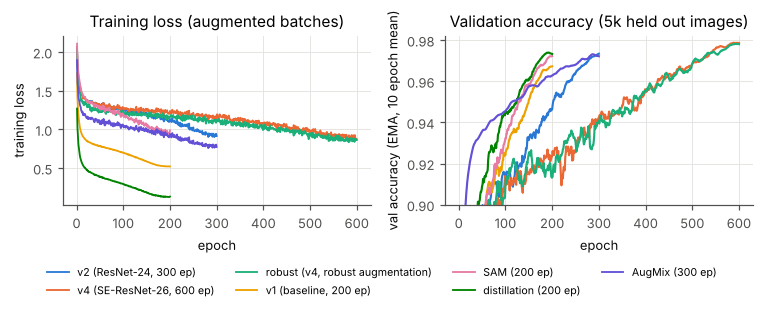

Don't compare loss values between runs: CutMix, label smoothing and distillation all change the targets,
so only the shape of each curve means anything. v1 trains on lightly augmented images and has no weight
averaging, which is why its loss is so much lower.


In [7]:
def log(run):
    return pd.read_csv(f"results/logs/{run}/train_log.csv")

curve_runs = [("v2", "v2", "v2 (ResNet-24, 300 ep)"), ("v4_val", "v4", "v4 (SE-ResNet-26, 600 ep)"),
              ("robust_val", "robust", "robust (v4, robust augmentation)"), ("v1", "v1", "v1 (baseline, 200 ep)"),
              ("v3_sam", "v3_sam", "SAM (200 ep)"), ("kd_val", "kd", "distillation (200 ep)"),
              ("augmix", "augmix", "AugMix (300 ep)")]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.0, 2.75))
for run, c, label in curve_runs:
    d = log(run); col = "val_acc_ema" if "val_acc_ema" in d else "val_acc"
    a1.plot(d.epoch, d.train_loss, color=COL[c], lw=1.2, label=label)
    smooth = d[col].rolling(10, min_periods=1, center=True).mean()     # average over 10 epochs so the curves are readable
    a2.plot(d.epoch, smooth, color=COL[c], lw=1.4, label=label)
a1.set(xlabel="epoch", ylabel="training loss", title="Training loss (augmented batches)")
a2.set(xlabel="epoch", ylabel="val accuracy (EMA, 10 epoch mean)", title="Validation accuracy (5k held out images)", ylim=(0.90, 0.982))
h, l = a1.get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, fontsize=7, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.11, 1, 1)); save(fig, "fig_curves"); plt.show()
print("Don't compare loss values between runs: CutMix, label smoothing and distillation all change the targets,"
      "\nso only the shape of each curve means anything. v1 trains on lightly augmented images and has no weight"
      "\naveraging, which is why its loss is so much lower.")

## 7. Validation accuracy against public and private leaderboard accuracy

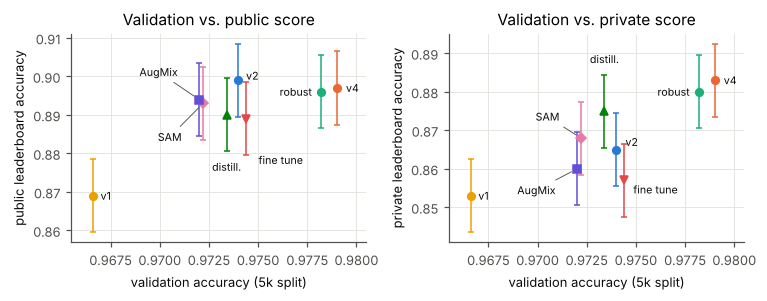

Error bars are one standard error of a score on 1,000 images: 0.95 points.


In [8]:
# Each submission is plotted at its own validation accuracy, or at that of the 45k run with the same settings
# if it was trained on all 50k images. The two v2 runs on all 50k images share v2's point, so we leave them out here.
pts = [("v1", "v1", "v1"), ("v2", "v2", "v2"), ("SAM", "v3_sam", "v3_sam"), ("AugMix", "augmix", "augmix"),
       ("distill.", "kd", "kd_full"), ("v4", "v4", "v4_full"), ("robust", "robust", "robust_full"), ("fine tune", "hardview", "hardview")]
twin = {"kd_full": "kd_val", "v4_full": "v4_val", "robust_full": "robust_val"}
se = np.sqrt(0.9 * 0.1 / 1000)                         # standard error of a score on 1,000 images
mk = {"SAM": "D", "AugMix": "s", "distill.": "^", "fine tune": "v"}
off = {"public": {"v1": (5, 0, "left", 0), "v2": (5, 3, "left", 0), "SAM": (-14, -22, "right", 1), "AugMix": (-14, 18, "right", 1),
                  "distill.": (0, -34, "center", 0), "v4": (6, 0, "left", 0), "robust": (-6, 0, "right", 0), "fine tune": (8, -27, "left", 0)},
       "private": {"v1": (5, 0, "left", 0), "v2": (6, 5, "left", 0), "SAM": (-14, 14, "right", 1), "AugMix": (-14, -14, "right", 1),
                   "distill.": (0, 34, "center", 0), "v4": (6, 0, "left", 0), "robust": (-6, 0, "right", 0), "fine tune": (6, -6, "left", 0)}}
fig, axs = plt.subplots(1, 2, figsize=(7.0, 2.8), sharex=True)
for ax, which in zip(axs, ["public", "private"]):
    for name, c, run in pts:
        v = float(runs.loc[twin.get(run, run), "val_flip"]); p = float(runs.loc[run, which])
        ax.errorbar(v, p, yerr=se, fmt=mk.get(name, "o"), ms=5, color=COL[c], ecolor=COL[c], elinewidth=1, capsize=2)
        dx, dy, ha, arrow = off[which][name]
        ax.annotate(name, (v, p), xytext=(dx, dy), textcoords="offset points", fontsize=7, color=INK, ha=ha, va="center",
                    arrowprops=dict(arrowstyle="-", color=INK2, lw=0.6, shrinkA=1, shrinkB=4) if arrow else None)
    ax.set(xlabel="validation accuracy (5k split)", ylabel=f"{which} leaderboard accuracy", title=f"Validation vs. {which} score",
           xlim=(0.9655, 0.9805))
fig.tight_layout(); save(fig, "fig_val_vs_public"); plt.show()
print(f"Error bars are one standard error of a score on 1,000 images: {100 * se:.2f} points.")

## 8. Robustness scorecard (our validation images with shifts applied)

         clean  bright+15%  contrast+25%  sharpen x2  blur s0.7  grayscale  jpeg q60  noise 0.04  shifted-mean
v2      0.9740      0.9722        0.9710      0.9672     0.9428     0.9520    0.8386      0.9116        0.9365
v4      0.9790      0.9774        0.9776      0.9742     0.9568     0.9580    0.8270      0.9280        0.9427
robust  0.9782      0.9780        0.9768      0.9726     0.9744     0.9588    0.8504      0.9298        0.9487


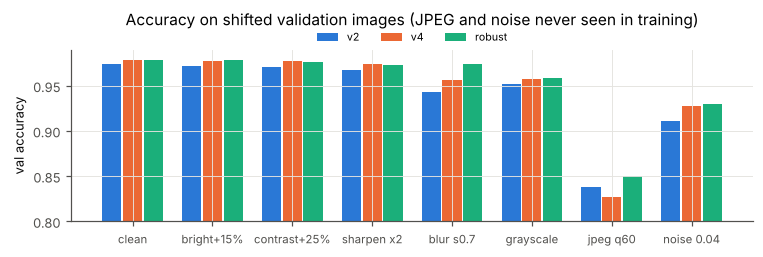


AugMix run (run 5) on its own benchmark of seven corruptions, validation accuracy:
           set  val_acc
         clean   0.9720
gaussian_noise   0.7392
 gaussian_blur   0.9550
      pixelate   0.4196
          jpeg   0.6776
    brightness   0.9426
      contrast   0.9256
      saturate   0.9640
  corrupt_mean   0.8034


In [9]:
pat = re.compile(r"SCORECARD (\S+ \S+)\s.*?clean ([\d.]+) \| shifted-mean ([\d.]+) \| (.*)")
score = {}
for line in open("results/logs/robust_val/stdout.log"):
    m = pat.search(line)
    if m:
        kv = re.findall(r"(\S+(?: x2| s0\.7| q60| 0\.04|\+\d+%)?) ([\d.]+)", m.group(4))
        score[m.group(1)] = {"clean": float(m.group(2)), **{k: float(v) for k, v in kv}, "shifted-mean": float(m.group(3))}
sc = pd.DataFrame(score).T.rename(index={"ref resnet-4-4-3": "v2", "ref resnet-5-4-3-se": "v4",
                                          "NEW resnet-5-4-3-se": "robust"}).loc[["v2", "v4", "robust"]]
print(sc.round(4).to_string()); sc.to_csv("results/robustness_scorecard.csv")

conds = [c for c in sc.columns if c not in ("clean", "shifted-mean")]
xs = np.arange(len(conds) + 1); w = 0.26
fig, ax = plt.subplots(figsize=(7.0, 2.4))
for i, run in enumerate(["v2", "v4", "robust"]):
    vals = [sc.loc[run, "clean"]] + [sc.loc[run, c] for c in conds]
    ax.bar(xs + (i - 1) * w, vals, width=w - 0.02, color=COL[run], label=run)
ax.set_xticks(xs, ["clean"] + conds, fontsize=7.5); ax.set_ylim(0.80, 0.99)
ax.set(ylabel="val accuracy")
ax.set_title("Accuracy on shifted validation images (JPEG and noise never seen in training)", pad=16)
ax.legend(ncol=3, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.0), borderaxespad=0.2)
fig.tight_layout(); save(fig, "fig_scorecard"); plt.show()

mw = pd.read_csv("results/logs/augmix/robustness.csv")
print("\nAugMix run (run 5) on its own benchmark of seven corruptions, validation accuracy:")
print(mw[mw.net == "ema"][["set", "val_acc"]].round(4).to_string(index=False))

## 9. How the test images differ from the training images (pixels only, no labels)

                          train (50k)  test (2k)  test / train
mean intensity                 0.4734     0.4907        1.0365
per-image contrast (std)       0.2110     0.2197        1.0408
edge energy (mean |dx|)        0.0540     0.0586        1.0847
fraction grayscale             0.0112     0.0330        2.9359


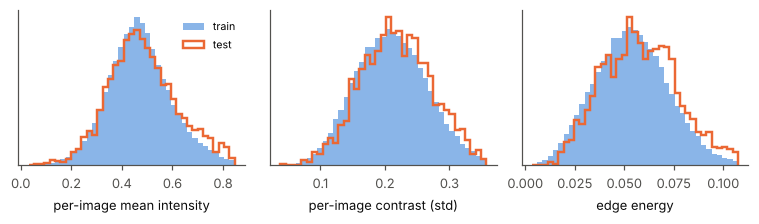

In [10]:
def img_stats(A, chunk=5000):
    out = {"mean": [], "contrast": [], "edge": [], "gray": []}
    for k in range(0, len(A), chunk):      # float64 in chunks; float32 sums over 150M values lose precision
        a = A[k:k + chunk].astype(np.float64) / 255
        out["mean"].append(a.mean((1, 2, 3))); out["contrast"].append(a.std((1, 2, 3)))
        out["edge"].append(np.abs(np.diff(a, axis=2)).mean((1, 2, 3)))
        out["gray"].append((np.abs(a[..., 0] - a[..., 1]).max((1, 2)) < 1e-9) & (np.abs(a[..., 1] - a[..., 2]).max((1, 2)) < 1e-9))
    return {k: np.concatenate(v) for k, v in out.items()}
S_tr, S_te = img_stats(X), img_stats(Xte)
tab = pd.DataFrame({
    "train (50k)": [S_tr["mean"].mean(), S_tr["contrast"].mean(), S_tr["edge"].mean(), S_tr["gray"].mean()],
    "test (2k)": [S_te["mean"].mean(), S_te["contrast"].mean(), S_te["edge"].mean(), S_te["gray"].mean()]},
    index=["mean intensity", "per-image contrast (std)", "edge energy (mean |dx|)", "fraction grayscale"])
tab["test / train"] = tab["test (2k)"] / tab["train (50k)"]
print(tab.round(4).to_string()); tab.to_csv("results/test_shift_stats.csv")

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.1))
for ax, key, lab in zip(axs, ["mean", "contrast", "edge"], ["per-image mean intensity", "per-image contrast (std)", "edge energy"]):
    bins = np.linspace(min(S_tr[key].min(), S_te[key].min()), np.percentile(np.r_[S_tr[key], S_te[key]], 99.5), 40)
    ax.hist(S_tr[key], bins=bins, density=True, color=COL["v2"], alpha=0.55, label="train")
    ax.hist(S_te[key], bins=bins, density=True, histtype="step", lw=1.6, color=COL["v4"], label="test")
    ax.set(xlabel=lab, yticks=[]); ax.grid(False)
axs[0].legend(fontsize=7)
fig.tight_layout(); save(fig, "fig_shift"); plt.show()

## 10. How noisy is a leaderboard of 1,000 images?

In [11]:
subs = ["v2", "v3_full", "v3_sam", "augmix", "v2full_nogray", "kd_full", "v4_full", "robust_full"]
P = {r: pd.read_csv(f"results/submissions/{r}.csv").sort_values("id").label.values for r in subs}
D = pd.DataFrame([[(P[a] != P[b]).mean() for b in subs] for a in subs], index=subs, columns=subs)
print("Percent of the 2,000 test images where two submissions give different answers:")
print((100 * D).round(1).to_string())
off = D.values[np.triu_indices(len(subs), 1)]
d = np.median(off)
n = d * 1000
print(f"\nA typical pair of submissions disagrees on {100 * d:.1f}% of images, about {n:.0f} of the 1,000 public ones.")
print(f"Only those images can separate two models. If the models are equally good, each one is a coin toss,"
      f"\nso the gap between their scores typically swings by about sqrt({n:.0f}) = {np.sqrt(n):.0f} images,"
      f" or {100 * np.sqrt(d / 1000):.1f} points.")
print("Our public scores after v2 run from 0.890 to 0.899, which is about what that noise alone would give.")

from scipy.stats import spearmanr
sub_runs = ["v1", "v2", "v3_full", "v3_sam", "augmix", "v2full_nogray", "kd_full", "v4_full", "robust_full", "hardview"]
twin_val = {"v3_full": "v2", "v2full_nogray": "v2", "kd_full": "kd_val", "v4_full": "v4_val", "robust_full": "robust_val"}
T = pd.DataFrame({"val": [float(runs.loc[twin_val.get(r, r), "val_flip"]) for r in sub_runs],
                  "public": [float(runs.loc[r, "public"]) for r in sub_runs],
                  "private": [float(runs.loc[r, "private"]) for r in sub_runs]}, index=sub_runs)
T["public rank"] = T.public.rank(ascending=False, method="min").astype(int)
T["private rank"] = T.private.rank(ascending=False, method="min").astype(int)
print("\nAll 10 submissions, public against private:")
print(T.sort_values("private", ascending=False).to_string())
print(f"\nOn average, the private score is {100 * (T.public - T.private).mean():.2f} points below the public one.")
print(f"How well each one ranks the submissions the same way as the private score (Spearman): "
      f"validation {spearmanr(T.iloc[:, 0], T.private)[0]:.2f}, public score {spearmanr(T.public, T.private)[0]:.2f}."
      f"\nWith only 10 submissions this is a rough guide, but validation was the better one to trust.")

Percent of the 2,000 test images where two submissions give different answers:
                v2  v3_full  v3_sam  augmix  v2full_nogray  kd_full  v4_full  robust_full
v2             0.0      5.9     6.6     7.0            6.8      5.3      5.6          6.4
v3_full        5.9      0.0     5.9     7.4            6.0      5.1      5.8          6.5
v3_sam         6.6      5.9     0.0     7.4            6.1      4.4      6.4          7.0
augmix         7.0      7.4     7.4     0.0            6.7      6.4      6.9          6.4
v2full_nogray  6.8      6.0     6.1     6.7            0.0      4.8      5.9          6.8
kd_full        5.3      5.1     4.4     6.4            4.8      0.0      5.4          5.4
v4_full        5.6      5.8     6.4     6.9            5.9      5.4      0.0          5.9
robust_full    6.4      6.5     7.0     6.4            6.8      5.4      5.9          0.0

A typical pair of submissions disagrees on 6.2% of images, about 62 of the 1,000 public ones.
Only those image


All 10 submissions, public against private:
                  val  public  private  public rank  private rank
v4_full        0.9790   0.897    0.883            3             1
robust_full    0.9782   0.896    0.880            4             2
kd_full        0.9734   0.890    0.875            7             3
v3_full        0.9740   0.890    0.870            7             4
v2full_nogray  0.9740   0.898    0.869            2             5
v3_sam         0.9722   0.893    0.868            6             6
v2             0.9740   0.899    0.865            1             7
augmix         0.9720   0.894    0.860            5             8
hardview       0.9744   0.889    0.857            9             9
v1             0.9666   0.869    0.853           10            10

On average, the private score is 2.35 points below the public one.
How well each one ranks the submissions the same way as the private score (Spearman): validation 0.62, public score 0.43.
With only 10 submissions this is a roug

## Summary

In [12]:
print(f"Final model: SE-ResNet-26 (64/128/256 channels, 5/4/3 blocks, SE gates), {N_FINAL:,} trainable parameters")
print(f"Validation accuracy, recomputed here: v4 {recomputed['v4_val']:.4f}, robust {recomputed['robust_val']:.4f}, v2 {recomputed['v2']:.4f}")
for run in ["v4_full", "robust_full"]:
    print(f"Kaggle accuracy, {run}: public {float(runs.loc[run].public):.3f}, private {float(runs.loc[run].private):.3f}")
print(f"Final result: private accuracy {lb.private_score:.3f}, rank {int(lb.private_rank)}")

Final model: SE-ResNet-26 (64/128/256 channels, 5/4/3 blocks, SE gates), 4,810,754 trainable parameters
Validation accuracy, recomputed here: v4 0.9790, robust 0.9782, v2 0.9740
Kaggle accuracy, v4_full: public 0.897, private 0.883
Kaggle accuracy, robust_full: public 0.896, private 0.880
Final result: private accuracy 0.883, rank 11
